# **Main Analysis**

In [ ]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
import matplotlib.pyplot as plt

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float32   # float16 is slow or unsupported on CPU

model_name = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, dtype=dtype).to(device)
# model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.bfloat16).to(device)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [ ]:
# test to see if the model works
msgs = [{"role": "user", "content": "Describe the view of earth from various heights."}]
inputs = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt").to(device)
outs = model.generate(**inputs, max_new_tokens=128)
print(tok.decode(outs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))

The Earth as viewed from different altitudes is a fascinating and complex phenomenon that showcases the vastness and diversity of our planet's surface. Here’s a description of how we can look at it from various perspectives:

1. **From the Moon:**
   - From the perspective of the Moon, the Earth appears to be an almost flat sphere due to its relatively small size compared to the distance between us and the Sun.
   - The curvature of the Earth is negligible for distances less than about 380,000 km (240,000 miles), making it appear much larger.

2. **From Mars


In [ ]:
# Prompt sets: 40 matched quintuples (bright, dark, neutral, hot, cold).
# Items 1-21: a previously existing sets, unchanged.
# Items 22-40: new. Written to avoid the leaks found earlier:
#   - no sun / blaze / glow / scorch (bright <-> hot leak), no winter / night (dark <-> cold leak)
#   - no mood words in dark ("gloomy", "heavy", "shadowy")
#   - dark sentences avoid the words "lit" / "light" (less word overlap with bright)
#   - neutral = boring properties (size, material, contents)
# Prompt sets drafted with AI assistance and reviewed by hand.

bright = [
    "The room was flooded with sunlight.",
    "The street was illuminated by streetlights.",
    "It was a sunny morning.",
    "The hallway glowed with warm lamplight.",
    "The stage was lit by blazing spotlights.",
    "Sunlight poured into the classroom.",
    "The parking lot was brightly lit.",
    "The kitchen was bright and sunny.",
    "The forest clearing was bathed in light.",
    "Her office was full of bright light.",
    "The beach shimmered under a blazing sky.",
    "The warehouse was brilliantly lit.",
    "The screen was far too bright.",
    "The bedroom was filled with morning light.",
    "The library was brightly lit.",
    "The city skyline blazed with light.",
    "The attic was surprisingly bright.",
    "The road ahead was clearly lit.",
    "The garden glowed in the noon sun.",
    "The lobby was dazzlingly bright.",
    "Lightbulbs shone over the corner.",
    # --- new (22-40) ---
    "The bathroom was brightly lit.",
    "The garage was lit by bright lamps.",
    "The staircase was well lit.",
    "The waiting room was brightly lit.",
    "The bus was bright inside.",
    "Bright lamps lined the train platform.",
    "The gym was flooded with bright light.",
    "The conference room was very bright.",
    "The hotel room was bright.",
    "Floodlights lit up the courtyard.",
    "The cafeteria lights were all on.",
    "The studio was lit with bright lamps.",
    "Electric lights lit up the barn.",
    "The church was full of bright light.",
    "The store was dazzlingly bright.",
    "Bright light filled the museum hall.",
    "The laboratory was extremely bright.",
    "The balcony was too bright to look at.",
    "The elevator was blindingly bright.",
]

dark = [
    "The room was pitch-black.",
    "The street was barely lit.",
    "It was a dark morning.",
    "The hallway sat in total darkness.",
    "The stage was lost in deep shadow.",
    "Darkness settled over the classroom.",
    "The parking lot was completely unlit.",
    "The kitchen was dark and gloomy.",
    "The forest clearing was swallowed by shadow.",
    "Her office was full of deep shadows.",
    "The beach lay under a moonless sky.",
    "The warehouse was pitch black.",
    "The screen was far too dim.",
    "The bedroom was filled with heavy darkness.",
    "The library was dimly lit.",
    "The city skyline was blacked out.",
    "The attic was surprisingly dim.",
    "The road ahead was hidden in darkness.",
    "The garden faded into the murk.",
    "The lobby was dark and shadowy.",
    "Shadows covered the corner.",
    # --- new (22-40) ---
    "The bathroom was completely dark.",
    "The garage was too dark to see.",
    "The staircase was in darkness.",
    "The waiting room was dark.",
    "The bus was dark inside.",
    "Darkness covered the train platform.",
    "The gym was in total darkness.",
    "The conference room was very dark.",
    "The hotel room was dim.",
    "Darkness swallowed the courtyard.",
    "The cafeteria was pitch dark.",
    "The studio sat in darkness.",
    "The barn was dark inside.",
    "The church was full of darkness.",
    "The store was completely dark.",
    "Shadows filled the museum hall.",
    "The laboratory was extremely dark.",
    "The balcony was too dark to make out.",
    "The elevator was utterly dark.",
]

neutral = [
    "The room was tidy.",
    "The street was well maintained.",
    "It was a Tuesday morning.",
    "The hallway had a long carpet.",
    "The stage was built from old planks.",
    "Students filed into the classroom.",
    "The parking lot was mostly empty.",
    "The kitchen was small and square.",
    "The forest clearing was covered in moss.",
    "Her office was full of old books.",
    "The beach stretched under a wide sky.",
    "The warehouse was recently sold.",
    "The screen was far too small.",
    "The bedroom was filled with cardboard boxes.",
    "The library was newly renovated.",
    "The city skyline was full of cranes.",
    "The attic was surprisingly spacious.",
    "The road ahead was freshly paved.",
    "The garden grew along the fence.",
    "The lobby was wide and carpeted.",
    "Boxes filled the corner.",
    # --- new (22-40) ---
    "The bathroom was recently tiled.",
    "The garage was full of old tools.",
    "The staircase was made of oak.",
    "The waiting room was half full.",
    "The bus was mostly empty inside.",
    "Benches lined the train platform.",
    "The gym was filled with new equipment.",
    "The conference room was very large.",
    "The hotel room was spacious.",
    "Tables filled the courtyard.",
    "The cafeteria was newly painted.",
    "The studio sat above a shop.",
    "The barn was full of hay.",
    "The church was full of wooden pews.",
    "The store was fully stocked.",
    "Statues filled the museum hall.",
    "The laboratory was extremely tidy.",
    "The balcony was too narrow to sit on.",
    "The elevator was oddly narrow.",
]

hot = [
    "The room was sweltering hot.",
    "The street was baking in the heat.",
    "It was a scorching morning.",
    "The hallway was stiflingly hot.",
    "The stage was sweltering.",
    "Heat filled the classroom.",
    "The parking lot was baking hot.",
    "The kitchen was hot and steamy.",
    "The forest clearing was stiflingly warm.",
    "Her office was full of stifling heat.",
    "The beach baked under a scorching sky.",
    "The warehouse was boiling hot.",
    "The screen was far too hot.",
    "The bedroom was filled with sticky heat.",
    "The library was uncomfortably hot.",
    "The city skyline sweltered in the heat.",
    "The attic was surprisingly hot.",
    "The road ahead was baking in the heat.",
    "The garden wilted in the noon heat.",
    "The lobby was sweltering and stuffy.",
    "Radiators warmed the corner.",
    # --- new (22-40) ---
    "The bathroom was hot and humid.",
    "The garage was hot and stuffy.",
    "The staircase was sweltering.",
    "The waiting room was stiflingly hot.",
    "The bus was hot inside.",
    "Heat hung over the train platform.",
    "The gym was filled with humid heat.",
    "The conference room was very warm.",
    "The hotel room was hot.",
    "Heat filled the courtyard.",
    "The cafeteria was boiling hot.",
    "The studio was sweltering and stuffy.",
    "The barn was hot inside.",
    "The church was full of stuffy heat.",
    "The store was unbearably hot.",
    "Heat filled the museum hall.",
    "The laboratory was extremely hot.",
    "The balcony was too hot to sit on.",
    "The elevator was stiflingly hot.",
]

cold = [
    "The room was freezing cold.",
    "The street was covered in frost.",
    "It was a freezing morning.",
    "The hallway was icy cold.",
    "The stage was frigid.",
    "Cold filled the classroom.",
    "The parking lot was bitterly cold.",
    "The kitchen was cold and drafty.",
    "The forest clearing was frozen solid.",
    "Her office was full of icy drafts.",
    "The beach froze under a wintry sky.",
    "The warehouse was freezing cold.",
    "The screen was far too cold.",
    "The bedroom was filled with bitter cold.",
    "The library was uncomfortably cold.",
    "The city skyline was locked in frost.",
    "The attic was surprisingly cold.",
    "The road ahead was slick with ice.",
    "The garden froze in the bitter chill.",
    "The lobby was frigid and drafty.",
    "Frost covered the corner.",
    # --- new (22-40) ---
    "The bathroom was icy cold.",
    "The garage was cold and drafty.",
    "The staircase was freezing.",
    "The waiting room was bitterly cold.",
    "The bus was cold inside.",
    "Cold air hung over the train platform.",
    "The gym was filled with chilly air.",
    "The conference room was very chilly.",
    "The hotel room was cold.",
    "Icy air filled the courtyard.",
    "The cafeteria was freezing cold.",
    "The studio was frigid and drafty.",
    "The barn was cold inside.",
    "The church was full of cold air.",
    "The store was unbearably cold.",
    "Chilly air filled the museum hall.",
    "The laboratory was extremely cold.",
    "The balcony was too cold to sit on.",
    "The elevator was icy cold.",
]

# Cleaned variants of the original items that carried connotations or cross-pair leaks.
# it's a potential leak, not a definitive one.
CLEAN_SWAPS = {
    # bright: sun/blaze -> heat leak, "sunny" mood
    "The beach shimmered under a blazing sky.": "Floodlights lit up the beach.",
    "The stage was lit by blazing spotlights.": "The stage was lit by powerful spotlights.",
    "The city skyline blazed with light.": "The city skyline sparkled with lights.",
    "The garden glowed in the noon sun.": "Lamps lit up the garden.",
    "It was a sunny morning.": "It was a bright morning.",
    "The kitchen was bright and sunny.": "The kitchen was bright and well lit.",
    # dark: mood, metaphor, time of day
    "It was a dark morning.": "It was a dim morning.",
    "The kitchen was dark and gloomy.": "The kitchen was dark and unlit.",
    "The bedroom was filled with heavy darkness.": "The bedroom was completely dark.",
    "The garden faded into the murk.": "The garden was too dark to see.",
    "The beach lay under a moonless sky.": "The beach was unlit.",
    "The city skyline was blacked out.": "The city skyline had no lights on.",
    "The lobby was dark and shadowy.": "The lobby was dark and unlit.",
    # hot: sun -> brightness leak, connotation
    "It was a scorching morning.": "It was a sweltering morning.",
    "The beach baked under a scorching sky.": "The beach sand was scalding hot.",
    "The kitchen was hot and steamy.": "The kitchen was hot and stuffy.",
    "The garden wilted in the noon heat.": "The garden wilted in the heat.",
    # cold: winter -> darkness leak
    "The beach froze under a wintry sky.": "The beach sand was icy cold.",
}

def cleaned(sentences):
    return [CLEAN_SWAPS.get(s, s) for s in sentences]

# Usage:
#   original: B, D, N, H, C = (get_all(x) for x in (bright, dark, neutral, hot, cold))
#   cleaned:  B, D, N, H, C = (get_all(cleaned(x)) for x in (bright, dark, neutral, hot, cold))

# get a collection of hidden states matrices from a set of sentences
def get_all(sentences):
    vecs = []
    for s in sentences:
        with torch.no_grad():
            enc = tok(s, return_tensors="pt").to(device)
            out = model(**enc, output_hidden_states=True) # do a forward pass to extract the hidden states
        vecs.append(torch.stack(out.hidden_states)[:, 0, -1].float())
    return torch.stack(vecs)   # size is [40, 25, 896]

In [ ]:
# B, D, N, H, C = (get_all(x) for x in (bright, dark, neutral, hot, cold))
B, D, N, H, C = (get_all(cleaned(x)) for x in (bright, dark, neutral, hot, cold))

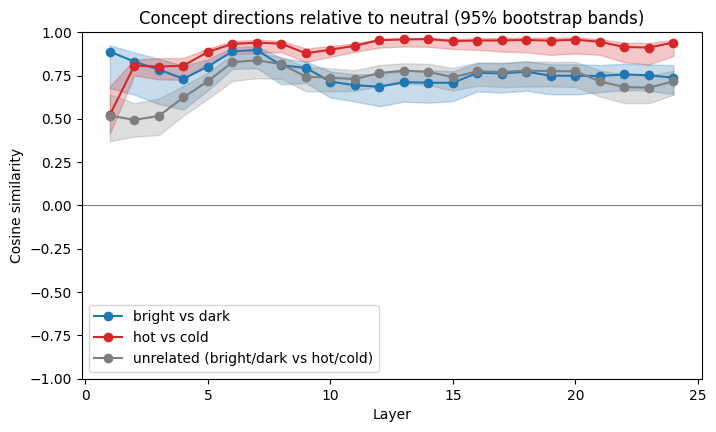

In [ ]:
# torch.manual_seed(311)
torch.manual_seed(42)
n_boot = 5000
n = B.shape[0]
layers = list(range(1, 25))

def cos_curve(a, b):
    # a, b: [25, 896] -> cosine at layers 1..24 in one go: [24]
    return F.cosine_similarity(a[1:25], b[1:25], dim=1)

def all_curves(vb, vd, vh, vc):
    return {
        "bright vs dark": cos_curve(vb, vd),
        "hot vs cold": cos_curve(vh, vc),
        # unrelated baseline: average of the 4 cross-pair cosines
        "unrelated (bright/dark vs hot/cold)": (cos_curve(vb, vh) + cos_curve(vb, vc)
                                                + cos_curve(vd, vh) + cos_curve(vd, vc)) / 4,
    }

# point estimates on the full data
nm = N.mean(0)
point = all_curves(*(X.mean(0) - nm for X in (B, D, H, C)))

# bootstrap (same idx for every set, so matched sentences stay together)
boot = {k: [] for k in point}
for _ in range(n_boot):
    idx = torch.randint(0, n, (n,))
    nm_b = N[idx].mean(0)
    curves = all_curves(*(X[idx].mean(0) - nm_b for X in (B, D, H, C)))
    for k, v in curves.items():
        boot[k].append(v)
boot = {k: torch.stack(v).cpu() for k, v in boot.items()}   # each [n_boot, 24]

# plot
plt.figure(figsize=(8, 4.5))
for (name, curves), color in zip(boot.items(), ["tab:blue", "tab:red", "tab:gray"]):
    lo = curves.quantile(0.025, dim=0).numpy()
    hi = curves.quantile(0.975, dim=0).numpy()
    plt.fill_between(layers, lo, hi, color=color, alpha=0.25)
    plt.plot(layers, point[name].cpu().numpy(), marker="o", color=color, label=name)
plt.axhline(0, color="gray", linewidth=0.8)
plt.ylim(-1, 1)
plt.xlabel("Layer")
plt.ylabel("Cosine similarity")
plt.title("Concept directions relative to neutral (95% bootstrap bands)")
plt.legend()
plt.savefig("cosine_all.png", dpi=150, bbox_inches="tight")
plt.show()

Gap, hot/cold minus bright/dark, layers 2-23: 95% interval [0.098, 0.229], fraction > 0 = 1.000
Gap, hot/cold minus unrelated baseline, layers 2-23: 95% interval [0.140, 0.235], fraction > 0 = 1.000
Unrelated baseline, mean over layers 2-23: 0.729


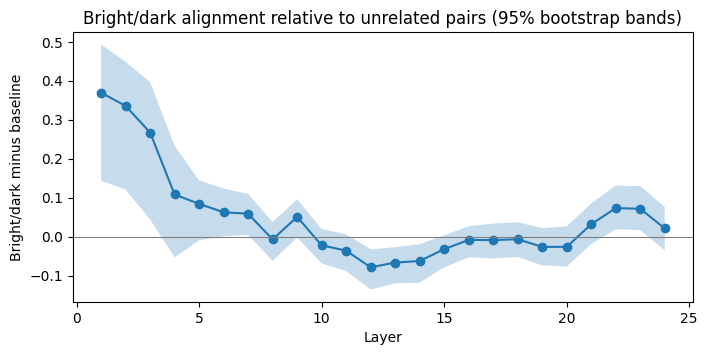

In [ ]:
def summarize(label, x):
    print(f"{label}: 95% interval [{x.quantile(0.025):.3f}, {x.quantile(0.975):.3f}], "
          f"fraction > 0 = {(x > 0).float().mean():.3f}")

no_ends = slice(1, 23)
summarize("Gap, hot/cold minus bright/dark, layers 2-23",
          boot["hot vs cold"][:, no_ends].mean(1) - boot["bright vs dark"][:, no_ends].mean(1))
summarize("Gap, hot/cold minus unrelated baseline, layers 2-23",
          boot["hot vs cold"][:, no_ends].mean(1) - boot["unrelated (bright/dark vs hot/cold)"][:, no_ends].mean(1))
print("Unrelated baseline, mean over layers 2-23:",
      round(point["unrelated (bright/dark vs hot/cold)"][1:23].mean().item(), 3))

diff = boot["bright vs dark"] - boot["unrelated (bright/dark vs hot/cold)"]   # [n_boot, 24]
point_diff = point["bright vs dark"] - point["unrelated (bright/dark vs hot/cold)"]

plt.figure(figsize=(8, 3.5))
plt.fill_between(layers, diff.quantile(0.025, dim=0).numpy(), diff.quantile(0.975, dim=0).numpy(), alpha=0.25)
plt.plot(layers, point_diff.cpu().numpy(), marker="o")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Layer")
plt.ylabel("Bright/dark minus baseline")
plt.title("Bright/dark alignment relative to unrelated pairs (95% bootstrap bands)")
plt.savefig("brightdark_minus_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

# **Robustness and Sanity Checks**

In [ ]:
# helper functions
def run_bootstrap(B, D, N, H, C, n_boot=5000, seed=42):
    torch.manual_seed(seed)
    n = B.shape[0]
    nm = N.mean(0)
    point = all_curves(*(X.mean(0) - nm for X in (B, D, H, C)))
    boot = {k: [] for k in point}
    for _ in range(n_boot):
        idx = torch.randint(0, n, (n,))
        nm_b = N[idx].mean(0)
        for k, v in all_curves(*(X[idx].mean(0) - nm_b for X in (B, D, H, C))).items():
            boot[k].append(v)
    return point, {k: torch.stack(v).cpu() for k, v in boot.items()}

def main_tests(point, boot, sl=slice(1, 23)):   # default: layers 2-23
    bd, hc, un = "bright vs dark", "hot vs cold", "unrelated (bright/dark vs hot/cold)"
    summarize("Hot/cold minus bright/dark", boot[hc][:, sl].mean(1) - boot[bd][:, sl].mean(1))
    summarize("Hot/cold minus baseline",    boot[hc][:, sl].mean(1) - boot[un][:, sl].mean(1))
    print("Baseline mean:", round(point[un][sl].mean().item(), 3))

In [ ]:
# sign consistency across layers for all comparisons
diffs = {
    "hot/cold - bright/dark": boot["hot vs cold"] - boot["bright vs dark"],
    "hot/cold - baseline":    boot["hot vs cold"] - boot["unrelated (bright/dark vs hot/cold)"],
}
L = range(2, 24)
for name, d in diffs.items():
    lo = d.quantile(0.025, dim=0)[1:23]
    hi = d.quantile(0.975, dim=0)[1:23]
    print(name)
    print("  layers with lower bound > 0:", int((lo > 0).sum()), "of 22")
    print("  not clearly positive:", [l for l, v in zip(L, lo) if v <= 0])
    print("  clearly reversed:", [l for l, v in zip(L, hi) if v < 0])

hot/cold - bright/dark
  layers with lower bound > 0: 19 of 22
  not clearly positive: [2, 3, 4]
  clearly reversed: []
hot/cold - baseline
  layers with lower bound > 0: 22 of 22
  not clearly positive: []
  clearly reversed: []


In [ ]:
# layer 1 exclusion justification
nm = N.mean(0)
for name, X in [("bright", B), ("dark", D), ("hot", H), ("cold", C)]:
    m = X.mean(0)
    v = m - nm
    rel = lambda l: (v[l].norm() / m[l].norm()).item()   # concept vector size relative to activation size
    print(f"{name}: layer 1 = {rel(1):.4f}, layer 12 = {rel(12):.4f}")

bright: layer 1 = 0.0669, layer 12 = 0.1940
dark: layer 1 = 0.0592, layer 12 = 0.2790
hot: layer 1 = 0.0542, layer 12 = 0.2647
cold: layer 1 = 0.0511, layer 12 = 0.2746


In [ ]:
main_tests(point, boot, sl=slice(0, 24))

Hot/cold minus bright/dark: 95% interval [0.082, 0.210], fraction > 0 = 1.000
Hot/cold minus baseline: 95% interval [0.138, 0.227], fraction > 0 = 1.000
Baseline mean: 0.72


In [ ]:
# split half stability, to check how similar two sets that are split from a concept set
g = torch.Generator().manual_seed(0)
n = B.shape[0]
for name, X in [("bright", B), ("dark", D), ("hot", H), ("cold", C)]:
    vals = []
    for _ in range(20):
        idx = torch.randperm(n, generator=g)
        a, b = idx[: n // 2], idx[n // 2 :]
        v1 = X[a].mean(0) - N[a].mean(0)
        v2 = X[b].mean(0) - N[b].mean(0)
        vals.append(F.cosine_similarity(v1[12], v2[12], dim=0).item())
    print(f"{name}: mean split-half cosine at layer 12 = {sum(vals) / len(vals):.3f}")

bright: mean split-half cosine at layer 12 = 0.800
dark: mean split-half cosine at layer 12 = 0.905
hot: mean split-half cosine at layer 12 = 0.881
cold: mean split-half cosine at layer 12 = 0.911


In [ ]:
Bo, Do, No, Ho, Co = (get_all(x) for x in (bright, dark, neutral, hot, cold))   # original wording
point_o, boot_o = run_bootstrap(Bo, Do, No, Ho, Co)
print("Original wording, 40 items:"); main_tests(point_o, boot_o)

point_21, boot_21 = run_bootstrap(Bo[:21], Do[:21], No[:21], Ho[:21], Co[:21])
print("Original wording, first 21 items:"); main_tests(point_21, boot_21)

Original wording, 40 items:
Hot/cold minus bright/dark: 95% interval [0.073, 0.191], fraction > 0 = 1.000
Hot/cold minus baseline: 95% interval [0.121, 0.209], fraction > 0 = 1.000
Baseline mean: 0.753
Original wording, first 21 items:
Hot/cold minus bright/dark: 95% interval [0.016, 0.233], fraction > 0 = 0.986
Hot/cold minus baseline: 95% interval [0.075, 0.215], fraction > 0 = 0.999
Baseline mean: 0.73
